# BÁO CÁO THÍ NGHIỆM: TÌM GIÁ TRỊ CUTOFF TỐI ƯU CHO MERGESORT

**Họ và tên:** Nguyễn Hoàng Linh

**Mã sinh viên:** 25021845

**Môn học:** Cấu trúc dữ liệu và giải thuật

## 1. Mục đích và cấu hình thí nghiệm
- **Mục đích:** Khảo sát và tìm giá trị `CUTOFF` (ngưỡng kích thước mảng để chuyển từ Mergesort sang Insertion Sort) đem lại hiệu năng thời gian tốt nhất.
- **Cấu hình phần cứng:** CPU [Intel Core i5-12450HX (12 CPUs) ~2.4GHz], RAM [16GB], Hệ điều hành [Windows 11].
- **Cấu hình phần mềm:** Java SE Development Kit 27 (JDK 27).
- **Tập dữ liệu (Dataset):** Các mảng số nguyên ngẫu nhiên kích thước $N = 10,000$, $N = 50,000$, $N = 100,000$ và $N = 500,000$. Dữ liệu được lưu tại `datasets.txt`.

## 2. Phương pháp thực hiện
Thí nghiệm duyệt qua các giá trị `CUTOFF` từ 0 (Mergesort thuần túy tới phần tử đơn lẻ) đến 20. Tại mỗi cấu hình, thuật toán được chạy 5 lần để tính thời gian trung bình (hạn chế sai số do hệ điều hành cấp phát tài nguyên).

In [83]:
import pandas as pd
from plotnine import ggplot, aes, geom_line, geom_point, labs, theme_minimal

df = pd.read_csv("results.csv")
summary_table = df.pivot(index='N', columns='CUTOFF', values='Time_ms')
with pd.option_context("display.max_columns", None):
    display(summary_table)

CUTOFF,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
N,,,,,,,,,,,,,,,,,,,,,
10000,8.573,3.864,4.653,4.056,8.807,2.329,2.187,2.280,2.164,2.354,2.172,2.170,2.005,2.347,1.797,1.624,1.597,1.576,1.830,1.748,1.716
50000,13.299,11.618,11.222,10.473,11.812,11.443,10.445,10.184,10.999,9.777,8.169,8.604,9.735,8.777,12.393,12.124,10.717,9.517,8.072,7.825,8.517
100000,20.959,18.078,19.690,22.626,24.034,29.851,32.536,26.029,21.092,19.376,23.141,26.168,22.266,25.836,24.834,25.270,30.457,25.758,27.622,19.775,22.301
500000,271.049,298.370,268.509,303.660,297.017,302.764,277.495,259.869,235.802,217.325,235.713,272.490,238.523,274.994,253.258,263.766,248.479,253.553,220.526,296.730,268.557


## 3. Kết quả đo đạc

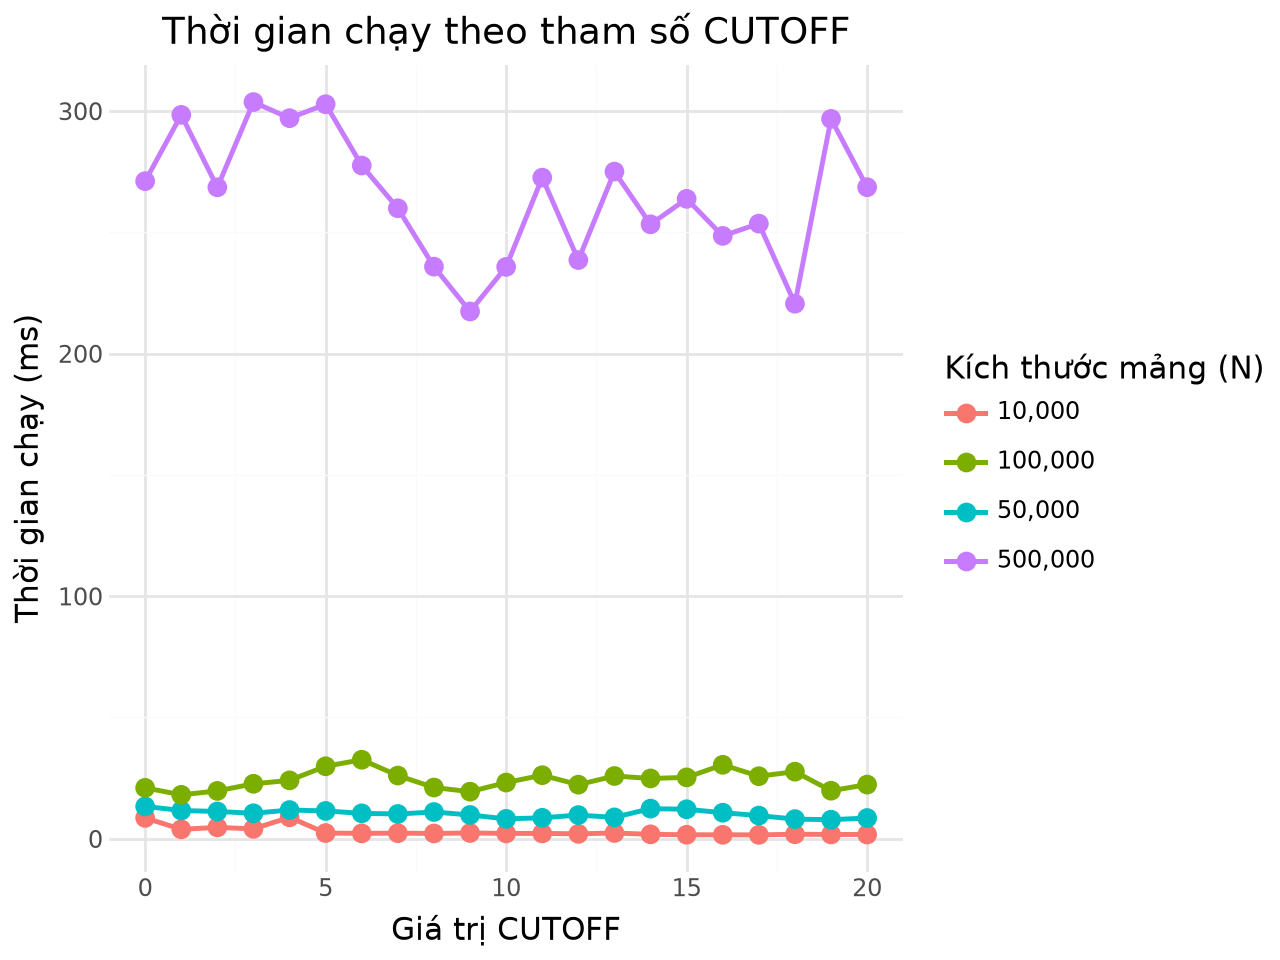

In [79]:
df['N_str'] = df['N'].apply(lambda x: f"{x:,}")

plot = (
    ggplot(df, aes(x='CUTOFF', y='Time_ms', color='N_str', group='N_str'))
    + geom_line(size=1)
    + geom_point(size=3)
    + labs(
        title="Thời gian chạy theo tham số CUTOFF",
        x="Giá trị CUTOFF",
        y="Thời gian chạy (ms)",
        color="Kích thước mảng (N)"
    )
    + theme_minimal()
)
plot.show()

import warnings
from plotnine.exceptions import PlotnineWarning

with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore", message=r"Saving .* in image\.", category=PlotnineWarning
    )
    warnings.filterwarnings(
        "ignore", message=r"Filename: .*", category=PlotnineWarning
    )
    plot.save("cutoff_analysis.png", width=10, height=6, dpi=300)

## 4. Phân tích và Kết luận
- **Hiện tượng quan sát được:** Khi `CUTOFF = 0`, thời gian chạy thường cao hơn do chi phí gọi hàm đệ quy (overhead) quá lớn đối với các mảng nhỏ. Khi tăng giá trị `CUTOFF` lên khoảng [7, 11], đường đồ thị đạt cực tiểu (thời gian chạy nhanh nhất). Nếu tiếp tục tăng `CUTOFF`, thời gian chạy lại bắt đầu tăng do Insertion Sort có độ phức tạp $O(N^2)$ bắt đầu bộc lộ nhược điểm trên mảng lớn hơn.
- **Giá trị tối ưu:** Đối với cấu hình máy đang sử dụng, giá trị `CUTOFF` tối ưu rơi vào khoảng **[9, 11]**. Điều này phù hợp với lý thuyết trong giáo trình đề xuất giá trị là 7 đến 10.